## Imports 

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import re
import seaborn as sns
from sklearn.model_selection import TimeSeriesSplit

SEED = 42

ruta_columnas = Path("..") / "data" / "processed" / "data_lineage.json"
df = pd.read_csv(ruta_datos, parse_dates=["DIA"])

Como tengo que guardar las columnas borradas así el pipeline toma las correctas, creo el json y una función para registrar.

In [ ]:
import json

ruta_columnas = Path("..") / "data" / "processed" / "tratamiento_columnas.json"
# arranca vacío en cada corrida: refleja solo los pasos que corrió esta notebook
registro_columnas = {}  
ruta_columnas.write_text(json.dumps(registro_columnas), encoding="utf-8")

def registrar_borradas(paso, columnas):
    """Guarda en el JSON las columnas borradas en un paso (pisa el paso si ya existía).
    Si alguna columna borrada tenía tratamientos registrados, se los quita."""
    registro_columnas[paso] = sorted(columnas)
    tratamientos = registro_columnas.get("tratamientos", {})
    for col in columnas:
        tratamientos.pop(col, None)
    ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"{paso}: {len(columnas)} columnas registradas en {ruta_columnas.name}")

def registrar_tratamiento(columnas, tratamiento):
    """Agrega el tratamiento a la lista de cada columna (clave 'tratamientos': {columna: [tratamientos en orden]}).
    Si la columna ya tiene ese tratamiento no lo repite (por si se vuelve a correr la celda)."""
    tratamientos = registro_columnas.setdefault("tratamientos", {})
    for col in columnas:
        lista = tratamientos.setdefault(col, [])
        if tratamiento not in lista:
            lista.append(tratamiento)
    ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"{tratamiento}: {len(columnas)} columnas registradas en {ruta_columnas.name}")

El tratamiento de valores nulos, de valores negativos y de columnas idénticas o en 0 se hace en `eda.ipynb` (queda registrado en `tratamiento_columnas_eda.json`). El CSV que lee esta notebook ya tiene que venir con esos pasos aplicados.

## Split Test/Train

In [30]:
df_sin_ident = df.sort_values("DIA").reset_index(drop=True)
n_eval = round(len(df_sin_ident) * 0.15)   # días de validación y de test

# Con test_size fijo y 2 cortes, TimeSeriesSplit da:
#   corte 1: train = lo más antiguo (70 %)      | evaluación = los 15 % siguientes (validación)
#   corte 2: train = train + validación (85 %)  | evaluación = el 15 % más reciente (test)
(idx_train, idx_val), (_, idx_test) = TimeSeriesSplit(n_splits=2, test_size=n_eval).split(df_sin_ident)
es_train = df_sin_ident.index.isin(idx_train)   # máscara para calcular los límites de outliers solo con train

for nombre, idx in [("Train", idx_train), ("Validación", idx_val), ("Test", idx_test)]:
    dias = df_sin_ident.loc[idx, "DIA"]
    print(f"{nombre:<11} {len(idx):>4} días ({len(idx) / len(df_sin_ident):.1%}) | {dias.min().date()} -> {dias.max().date()}")

# Se guardan los cortes para que el modelado y el pipeline usen exactamente los mismos
registro_columnas["split"] = {nombre: str(df_sin_ident.loc[idx, "DIA"].max().date())
                              for nombre, idx in [("fin_train", idx_train), ("fin_val", idx_val)]}
ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8")

Train        849 días (70.0%) | 2020-07-01 -> 2022-10-27
Validación   182 días (15.0%) | 2022-10-28 -> 2023-04-27
Test         182 días (15.0%) | 2023-04-28 -> 2023-10-26


15640

## Outliers

Voy a usar Z-Score para obtenerlos. Mi idea es poner umbrales grandes de outliers, por que estoy trabajando con 350 columnas y no voy a poder usar LOF (mucha dimensionalidad). 

Entonces, mi plan es usar Z-Score para sacar los ruidos muy molestos, y voy a usar transformaciones más tarde para llevar todo a una escala más trabajable.

In [31]:
UMBRAL_Z = 10   #  el estándar es 3.5, agarro 10 para que salten los más altos nada más

In [32]:
def outliers_zscore(datos, umbral=3, excluir=(), filas_ref=None, col_fecha="DIA"):
    """Z-score clásico por columna: |x - media| / desvío > umbral.

    La media y el desvío se calculan solo con las filas de `filas_ref` (máscara booleana, por ejemplo train)
    y se aplican a todas las filas. Si es None, usa todas.
    Ignora columnas binarias (en las filas de referencia) y las de `excluir`.
    Devuelve: tabla por columna (ordenada por z máx) y máscara de outliers (días x columnas).
    """
    x = datos.drop(columns=[col_fecha, *excluir]).select_dtypes("number")
    ref = x if filas_ref is None else x.loc[filas_ref]
    x = x.loc[:, ref.nunique() > 2]
    ref = ref[x.columns]

    z = ((x - ref.mean()) / ref.std()).abs()
    es_out = z > umbral

    fila_max = z.idxmax()
    tabla = pd.DataFrame({
        "n outliers": es_out.sum(),
        "z máx": z.max().round(1),
        "día z máx": datos.loc[fila_max, col_fecha].dt.date.to_numpy(),
        "valor z máx": [x.at[i, c] for c, i in fila_max.items()],
        "mediana": ref.median(),
    })
    tabla = tabla[tabla["n outliers"] > 0].sort_values("z máx", ascending=False)
    return tabla, es_out


def winsorizar_marcados(datos, mascara, p_inf=0.02, p_sup=0.98, filas_ref=None,
                        frio="Consolidado EE | Frio (Kw)", col_fecha="DIA"):
    """Lleva al percentil p_inf/p_sup de su columna SOLO las celdas marcadas en `mascara`.

    Los percentiles se calculan solo con las filas de `filas_ref` (si es None, con todas).
    El resto de la columna no se toca. Si se corrige Frio, recalcula el target (Frio de D+1).
    Devuelve el df corregido y la lista de columnas modificadas.
    """
    cols = list(mascara.columns[mascara.any()])
    x = datos[cols]
    ref = x if filas_ref is None else x.loc[filas_ref]
    recortado = x.clip(lower=ref.quantile(p_inf), upper=ref.quantile(p_sup), axis=1)

    df = datos.copy()
    df[cols] = x.where(~mascara[cols], recortado)

    if frio in cols:
        frio_nuevo = df.set_index(col_fecha)[frio]
        df["target"] = (df[col_fecha] + pd.Timedelta(days=1)).map(frio_nuevo).fillna(df["target"])
    return df, cols

Voy a hacer dos pasadas de z-score con un umbral muy alto. 

Mi idea es que el primer umbral alto tome los valores como el de frío, que tien 3 outliers muy grandes (y lo mismo para el resto de columnas). El segundo es el que va a trabajar con los outliers un poco más chicos que quedaron.

In [33]:
c_frio = "Consolidado EE | Frio (Kw)"
# Fuera del análisis: calendario (codificado a propósito), metas (rellenadas con 1 provisoriamente)
# y target (es Frio corrido un día: se corrige Frio y se recalcula)
calendario = [c for c in df_sin_ident.columns
              if c in ("DIA_SEMANA", "MES", "ESTACION", "FIN_SEMANA") or c.endswith(("_sin", "_cos"))]
metas = [c for c in df_sin_ident.columns if c.split(" | ", 1)[-1].strip().lower().startswith("meta")]
excluir_z = ["target", *calendario, *[c for c in metas if c in df_sin_ident.columns]]

tabla_z1, mascara_z1 = outliers_zscore(df_sin_ident, umbral=UMBRAL_Z, excluir=excluir_z, filas_ref=es_train)
df_out1, cols_out1 = winsorizar_marcados(df_sin_ident, mascara_z1, filas_ref=es_train)

print(f"Pasada 1 | umbral {UMBRAL_Z} | valores corregidos: {mascara_z1.sum().sum()} en {len(cols_out1)} columnas")
with pd.option_context("display.max_colwidth", None, "display.float_format", "{:,.2f}".format):
    display(tabla_z1.head(10))

print(f"Frio corregido en {mascara_z1[c_frio].sum()} días; target máximo: {df_out1['target'].max():,.0f}")

registrar_tratamiento(cols_out1, "winsor_p2_p98_si_zscore_pasada1")

Pasada 1 | umbral 10 | valores corregidos: 534 en 108 columnas


,n outliers,z máx,día z máx,valor z máx,mediana
Totalizadores Energia | KW Enfluentes Coc,4,"3,039.80",2023-06-28,"125,244.00",107.00
Consolidado EE | Efluentes (Kw),3,590.20,2023-06-28,"125,882.00",860.00
Totalizadores Agua | Red Paste L3,2,290.30,2022-12-26,"18,625.57",34.11
Totalizadores CO2 | Totalizador_L2_Barriles,251,99.50,2022-11-05,"4,831.00",0.00
Consolidado KPI | ET Linea 4/Hl,12,68.60,2023-02-27,500.03,6.29
Totalizadores Produccion | Hl Mosto Bieckert Urbana,3,40.10,2023-07-22,"2,432.00",0.00
Consolidado KPI | CO 2 Filtro / Hl,1,33.90,2023-09-16,6.00,0.42
Consolidado KPI | Agua Linea 4/Hl,8,32.80,2023-07-31,35.67,0.34
Consolidado EE | Envasado (Kw),1,29.10,2021-11-29,"4,504,000.00","16,770.00"
Totalizadores Energia | KW Linea 2,1,29.10,2021-11-29,"4,495,238.00","3,026.00"


Frio corregido en 3 días; target máximo: 56,128
winsor_p2_p98_si_zscore_pasada1: 108 columnas registradas en tratamiento_columnas.json


In [34]:
tabla_z2, mascara_z2 = outliers_zscore(df_out1, umbral=UMBRAL_Z, excluir=excluir_z, filas_ref=es_train)
df_out2, cols_out2 = winsorizar_marcados(df_out1, mascara_z2, filas_ref=es_train)

print(f"Pasada 2 | umbral {UMBRAL_Z} | valores corregidos: {mascara_z2.sum().sum()} en {len(cols_out2)} columnas "
      f"(train: {mascara_z2[es_train].sum().sum()} | validación + test: {mascara_z2[~es_train].sum().sum()})")
with pd.option_context("display.max_colwidth", None, "display.float_format", "{:,.2f}".format):
    display(tabla_z2.head(10))

registrar_tratamiento(cols_out2, "winsor_p2_p98_si_zscore_pasada2")

Pasada 2 | umbral 10 | valores corregidos: 191 en 72 columnas (train: 132 | validación + test: 59)


,n outliers,z máx,día z máx,valor z máx,mediana
Consolidado EE | Pta Agua / Eflu (Kw),1,361.30,2023-06-28,"126,429.00","1,630.00"
Totalizadores CO2 | Totalizador_L2_Barriles,27,61.00,2023-09-17,488.00,0.00
Consolidado KPI | EE Cocina / Hl,3,34.90,2023-08-10,7.76,0.29
Totalizadores Agua | Agua Cald,1,29.10,2021-08-07,"85,282.13",61.63
Totalizadores Agua | Glicol Paste L3,1,29.00,2020-12-29,2.92,0.00
Totalizadores Energia | KW Caldera 3,1,28.70,2021-09-24,"14,451.00",80.00
Consolidado KPI | Agua Linea 4/Hl,7,27.50,2023-07-24,10.45,0.34
Consolidado KPI | EE Elaboracion / Hl,1,27.30,2020-07-01,47.15,0.75
Totalizadores Produccion | HL Mosto Roja,2,26.70,2020-09-17,"3,165.00",0.00
Consolidado KPI | EE Agua / Hl,1,26.20,2021-09-25,13.81,0.08


winsor_p2_p98_si_zscore_pasada2: 72 columnas registradas en tratamiento_columnas.json


Registro en el json los valores así el pipeline lo reproduce bien.

In [35]:
def parametros_zscore(datos, excluir, filas_ref, p_inf=0.02, p_sup=0.98, col_fecha="DIA"):
    """Media, desvío y percentiles de train de las mismas columnas que analiza outliers_zscore
    (numéricas, no excluidas, con más de 2 valores distintos en train), para aplicarlos en predict.py."""
    x = datos.drop(columns=[col_fecha, *excluir]).select_dtypes("number")
    ref = x.loc[filas_ref]
    ref = ref.loc[:, ref.nunique() > 2]
    return {nombre: {c: float(v) for c, v in serie.items()}
            for nombre, serie in [("media", ref.mean()), ("desvio", ref.std()),
                                  ("p_inf", ref.quantile(p_inf)), ("p_sup", ref.quantile(p_sup))]}

registro_columnas["outliers"] = {
    "umbral": UMBRAL_Z,
    "excluir": excluir_z,
    "pasada1": parametros_zscore(df_sin_ident, excluir_z, es_train),
    "pasada2": parametros_zscore(df_out1, excluir_z, es_train),
}
ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Outliers registrados: pasada 1 {len(registro_columnas['outliers']['pasada1']['media'])} columnas | "
      f"pasada 2 {len(registro_columnas['outliers']['pasada2']['media'])} columnas")

Outliers registrados: pasada 1 238 columnas | pasada 2 235 columnas


Aplico para el test y validación:

In [36]:
df_train = df_out2.loc[idx_train].reset_index(drop=True)
df_val = df_out2.loc[idx_val].reset_index(drop=True)
df_test = df_out2.loc[idx_test].reset_index(drop=True)

for nombre, d in [("Train", df_train), ("Validación", df_val), ("Test", df_test)]:
    print(f"{nombre:<11} {d.shape}")

Train       (849, 309)
Validación  (182, 309)
Test        (182, 309)


## Feature Engineering

### Temperatura

Voy a usar a  open meteo para tomar los datos; planta esta en Tecate, Baja California.

In [37]:
from urllib.parse import urlencode
from urllib.request import urlopen


def descargar_temperatura(desde, hasta, ruta):
    """Baja de Open-Meteo la temperatura diaria de Tecate y la guarda en un CSV."""
    parametros = {
        "latitude": 32.5667,      # Tecate, Baja California
        "longitude": -116.6333,
        "start_date": desde,
        "end_date": hasta,
        "daily": "temperature_2m_mean,temperature_2m_max,temperature_2m_min",
        "timezone": "America/Tijuana",
    }
    url = "https://archive-api.open-meteo.com/v1/archive?" + urlencode(parametros)
    with urlopen(url, timeout=60) as respuesta:
        diario = json.load(respuesta)["daily"]

    temp = pd.DataFrame({
        "DIA": pd.to_datetime(diario["time"]),
        "TEMP_media": diario["temperature_2m_mean"],
        "TEMP_max": diario["temperature_2m_max"],
        "TEMP_min": diario["temperature_2m_min"],
    })
    ruta.parent.mkdir(parents=True, exist_ok=True)
    temp.to_csv(ruta, index=False)
    return temp

In [38]:
ruta_temp = Path("..") / "data" / "external" / "temperatura_tecate.csv"
if ruta_temp.exists():
    temp = pd.read_csv(ruta_temp, parse_dates=["DIA"])
else:
    hasta = (pd.Timestamp.today() - pd.Timedelta(days=7)).strftime("%Y-%m-%d")
    temp = descargar_temperatura("2020-06-01", hasta, ruta_temp)

print(f"Temperatura: {temp.shape} | {temp['DIA'].min().date()} -> {temp['DIA'].max().date()} "
      f"| nulos: {temp.isna().sum().sum()}")

Temperatura: (2351, 4) | 2020-06-01 -> 2026-11-07 | nulos: 0


Anda bien. Agrego las columnas: 

1 - La temperatura (que viene con la media del día, la mínima, máxima, y su diferencial comparado al día anterior).

In [39]:
def agregar_temperatura(datos, temp, col_fecha="DIA"):
    """Pega la temperatura del día D y su variación contra el día anterior (> 0: está subiendo).
    La variación se calcula sobre la tabla de temperatura (calendario continuo),
    así que funciona igual en cualquier conjunto aunque se procese por separado."""
    temp = temp.sort_values(col_fecha).copy()
    temp["TEMP_dif"] = temp["TEMP_media"].diff()
    return datos.merge(temp, on=col_fecha, how="left", validate="m:1")


In [40]:
df_train = agregar_temperatura(df_train, temp)
df_val = agregar_temperatura(df_val, temp)
df_test = agregar_temperatura(df_test, temp)

cols_temp = ["TEMP_media", "TEMP_max", "TEMP_min", "TEMP_dif"]
for nombre, d in [("Train", df_train), ("Validación", df_val), ("Test", df_test)]:
    print(f"{nombre:<11} {d.shape} | días sin temperatura: {d[cols_temp].isna().any(axis=1).sum()}")

Train       (849, 313) | días sin temperatura: 0
Validación  (182, 313) | días sin temperatura: 0
Test        (182, 313) | días sin temperatura: 0


2 - Tomo la media del frío de los últimos 5 días (y la derivada). 

In [41]:
def serie_con_previo(datos, columna, previo=None, col_fecha="DIA"):
    """Serie de `columna` indexada por fecha, con los días de `previo` adelante (si se pasa)."""
    partes = [datos[[col_fecha, columna]]] if previo is None else [previo[[col_fecha, columna]], datos[[col_fecha, columna]]]
    return pd.concat(partes).sort_values(col_fecha).set_index(col_fecha)[columna]


def media_movil(datos, columna, nombre, ventana, previo=None, col_fecha="DIA"):
    """Promedio de los últimos `ventana` días, incluyendo el día D (no usa datos futuros).
    `previo`: días anteriores a `datos`, para que los primeros días tengan historia."""
    resultado = serie_con_previo(datos, columna, previo, col_fecha).rolling(ventana, min_periods=1).mean()
    datos = datos.copy()
    datos[nombre] = datos[col_fecha].map(resultado)
    return datos


def variacion(datos, columna, nombre, previo=None, col_fecha="DIA"):
    """Diferencia contra el día anterior (> 0: está creciendo).
    Si no hay día anterior (inicio de la serie, sin `previo`), queda en 0."""
    resultado = serie_con_previo(datos, columna, previo, col_fecha).diff().fillna(0)
    datos = datos.copy()
    datos[nombre] = datos[col_fecha].map(resultado)
    return datos

In [42]:
# 1) Media de frío de los últimos 5 días (D-4 a D)
df_train = media_movil(df_train, c_frio, "FRIO_media5", ventana=5)
df_val = media_movil(df_val, c_frio, "FRIO_media5", ventana=5, previo=df_train)
df_test = media_movil(df_test, c_frio, "FRIO_media5", ventana=5, previo=pd.concat([df_train, df_val]))

# 2) Su variación: la historia tiene que tener FRIO_media5, por eso va después del paso 1
df_train = variacion(df_train, "FRIO_media5", "FRIO_media5_dif")
df_val = variacion(df_val, "FRIO_media5", "FRIO_media5_dif", previo=df_train)
df_test = variacion(df_test, "FRIO_media5", "FRIO_media5_dif", previo=pd.concat([df_train, df_val]))

for nombre, d in [("Train", df_train), ("Validación", df_val), ("Test", df_test)]:
    print(f"{nombre:<11} {d.shape} | nulos nuevos: {d[['FRIO_media5', 'FRIO_media5_dif']].isna().sum().sum()}")

Train       (849, 315) | nulos nuevos: 0
Validación  (182, 315) | nulos nuevos: 0
Test        (182, 315) | nulos nuevos: 0


3 - Tomo la media del frío para los últimos 14 días. 

In [43]:
# Media de frío de los últimos 14 días (D-13 a D)
df_train = media_movil(df_train, c_frio, "FRIO_media14", ventana=14)
df_val = media_movil(df_val, c_frio, "FRIO_media14", ventana=14, previo=df_train)
df_test = media_movil(df_test, c_frio, "FRIO_media14", ventana=14, previo=pd.concat([df_train, df_val]))

for nombre, d in [("Train", df_train), ("Validación", df_val), ("Test", df_test)]:
    print(f"{nombre:<11} {d.shape} | nulos nuevos: {d['FRIO_media14'].isna().sum()}")

Train       (849, 316) | nulos nuevos: 0
Validación  (182, 316) | nulos nuevos: 0
Test        (182, 316) | nulos nuevos: 0


### Producción

Viendo las columnas de consolidado producción:

In [44]:
[c for c in df_train.columns if c.startswith("Consolidado Produccion")]

['Consolidado Produccion | Hl de Mosto',
 'Consolidado Produccion | Hl Cerveza Cocina',
 'Consolidado Produccion | Hl Producido Bodega',
 'Consolidado Produccion | Hl Cerveza Filtrada',
 'Consolidado Produccion | Hl Cerveza Envasada',
 'Consolidado Produccion | Hl Cerveza L2',
 'Consolidado Produccion | Hl Cerveza L3',
 'Consolidado Produccion | Hl Cerveza L4',
 'Consolidado Produccion | Hl Cerveza L5']

Despues de buscar como funciona la cadena de producción de la cerveza, lo resumo en esto: 

- Molís, filtras, y hervís para llegar al mosto. Despues de hervirlo, se tiene que enfriar rapidamente para que no se arruine. 
    - Aca trabaja HL de Mosto, HL Cerveza Cocina.
- Dejas el mosto fermentando. Fermentar a su vez causa calor, por lo tanto hay que seguir enfriando para que no se arruine. Participa ahí Hl Producido Bodega.
- Se tiene que filtrar la cerveza a 0 grados 'para que no se enturbie', y los tanques de cerveza filtrada también quedan fríos. Trabaja Hl Cerveza Filtrada.
- Envasado son 4 líneas de producción, HL Cerveza Ln y su consolidado de Hl Cerveza envasada.


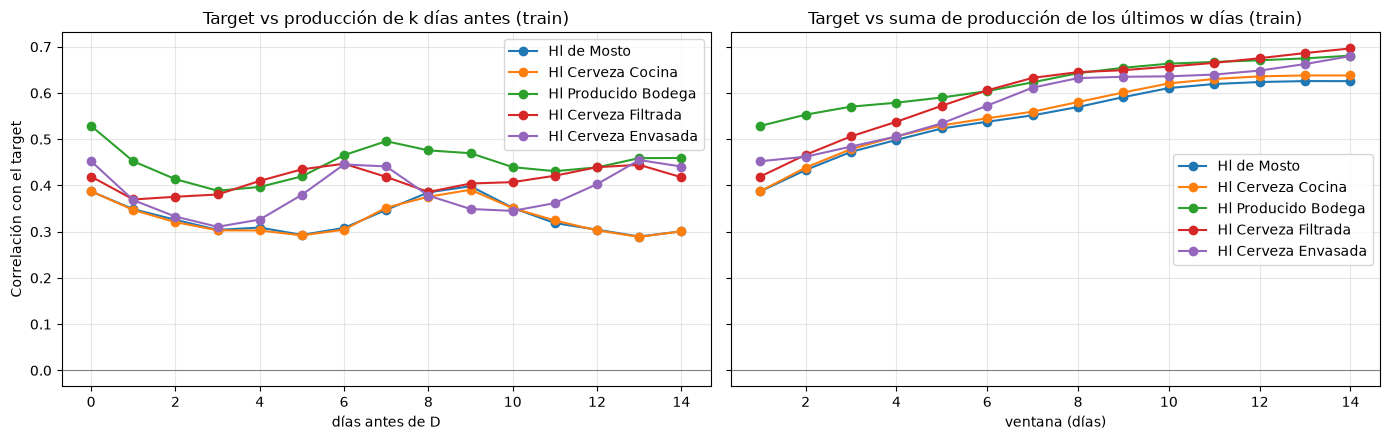

In [45]:
cols_prod = [
    "Consolidado Produccion | Hl de Mosto",
    "Consolidado Produccion | Hl Cerveza Cocina",
    "Consolidado Produccion | Hl Producido Bodega",
    "Consolidado Produccion | Hl Cerveza Filtrada",
    "Consolidado Produccion | Hl Cerveza Envasada",
]
faltan = [c for c in cols_prod if c not in df_train.columns]
print("No están en el df:", faltan) if faltan else None
cols_prod = [c for c in cols_prod if c in df_train.columns]

tr = df_train.sort_values("DIA")
rezagos = range(0, 15)
corto = {c: c.split(" | ", 1)[-1] for c in cols_prod}

# Correlación del target con la producción de k días antes de D
corr_rezago = pd.DataFrame({corto[c]: [tr["target"].corr(tr[c].shift(k)) for k in rezagos] for c in cols_prod},
                           index=pd.Index(rezagos, name="días antes de D"))

# Correlación del target con la suma de producción de los últimos w días (D-w+1 a D)
ventanas = range(1, 15)
corr_suma = pd.DataFrame({corto[c]: [tr["target"].corr(tr[c].rolling(w).sum()) for w in ventanas] for c in cols_prod},
                         index=pd.Index(ventanas, name="ventana (días)"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
corr_rezago.plot(ax=axes[0], marker="o", title="Target vs producción de k días antes (train)")
corr_suma.plot(ax=axes[1], marker="o", title="Target vs suma de producción de los últimos w días (train)")
axes[0].set_ylabel("Correlación con el target")
for ax in axes:
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

En el eje Y la correlación con frío, y en el eje X cuantos días tiene de diferencia con 0. 
Viendo el primer grafico, nos damos cuenta que el HL de cerveza envasada hace el pico a los 7 días, y despues vuelve a repetir el patrón. 

Hay un cambio semanal en la producción entonces. Bodega es la que más correlación tiene en el mismo día, y aumenta mucho la correlación para cerveza envasada y filtrada en el día 7. 

Con esto, conozco que hay una demora entre cada proceso y uso eso para crear las features: 
- Hago columnas que sean la producción hace 7 días para producido bodega y cerveza envasada. Filtrada ocurre un día antes, pero voy a mantenerlo en 7 por continuidad. 
- Para Cocina y mosto, parece que toma el valor máximo a los 9 días, así qeu las hago con esas. 

Aparte, le voy a hacer derivadas a los 4 sectores (a cocina y mosto no le hago uno por separado por que son iguales).

In [46]:
def rezago(datos, columna, nombre, k, previo=None, col_fecha="DIA"):
    """Valor de `columna` k días antes de D. Con `previo`, los primeros días toman la historia.
    Si no hay k días anteriores (inicio de la serie), usa el primer valor disponible."""
    resultado = serie_con_previo(datos, columna, previo, col_fecha).shift(k).bfill()
    datos = datos.copy()
    datos[nombre] = datos[col_fecha].map(resultado)
    return datos

In [47]:
# {columna: (sector, días de rezago)}
rezagos_prod = {
    "Consolidado Produccion | Hl de Mosto": ("mosto", 9),
    "Consolidado Produccion | Hl Cerveza Cocina": ("cocina", 9),
    "Consolidado Produccion | Hl Producido Bodega": ("bodega", 7),
    "Consolidado Produccion | Hl Cerveza Filtrada": ("filtrada", 7),
    "Consolidado Produccion | Hl Cerveza Envasada": ("envasada", 7),
}
# {columna: sector} para las derivadas (una por sector)
derivadas_prod = {
    "Consolidado Produccion | Hl Cerveza Cocina": "cocina",
    "Consolidado Produccion | Hl Producido Bodega": "bodega",
    "Consolidado Produccion | Hl Cerveza Filtrada": "filtrada",
    "Consolidado Produccion | Hl Cerveza Envasada": "envasada",
}


In [48]:
faltan = [c for c in {**rezagos_prod, **derivadas_prod, c_frio: None} if c not in df_train.columns]
assert not faltan, f"No están en el df: {faltan}"

nuevas = []
for col, (sector, k) in rezagos_prod.items():
    nombre = f"PROD_{sector}_lag{k}"
    df_train = rezago(df_train, col, nombre, k)
    df_val = rezago(df_val, col, nombre, k, previo=df_train)
    df_test = rezago(df_test, col, nombre, k, previo=pd.concat([df_train, df_val]))
    nuevas.append(nombre)

for col, sector in derivadas_prod.items():
    nombre = f"PROD_{sector}_dif"
    df_train = variacion(df_train, col, nombre)
    df_val = variacion(df_val, col, nombre, previo=df_train)
    df_test = variacion(df_test, col, nombre, previo=pd.concat([df_train, df_val]))
    nuevas.append(nombre)

# Frío del mismo día de la semana que D+1, una semana antes (D - 6)
df_train = rezago(df_train, c_frio, "FRIO_lag6", 6)
df_val = rezago(df_val, c_frio, "FRIO_lag6", 6, previo=df_train)
df_test = rezago(df_test, c_frio, "FRIO_lag6", 6, previo=pd.concat([df_train, df_val]))
nuevas.append("FRIO_lag6")

print(f"Columnas nuevas: {len(nuevas)}")
for nombre, d in [("Train", df_train), ("Validación", df_val), ("Test", df_test)]:
    print(f"{nombre:<11} {d.shape} | nulos nuevos: {d[nuevas].isna().sum().sum()}")
print(f"Corr con target (train): FRIO_lag6 {df_train['FRIO_lag6'].corr(df_train['target']):.3f} | "
      f"Frio de D {df_train[c_frio].corr(df_train['target']):.3f}")

Columnas nuevas: 10
Train       (849, 326) | nulos nuevos: 0
Validación  (182, 326) | nulos nuevos: 0
Test        (182, 326) | nulos nuevos: 0
Corr con target (train): FRIO_lag6 0.732 | Frio de D 0.843


### Ratios de Producción

Se sugieren ratios de producción, pero como no encuentro una buena relación base para armarlos a mano, lo que voy a hacer es armar una columna de ratio para cada parte de producción: (Zona_Producción / Frio). 

La idea es que te diga cuantos Hl de cada etapa pasan por cada Kw de frío, entonces al modelo le da una relación entre Kw y Hl. Ya existen relaciones parecidas en las columnas, pero las voy a dejar y en todo caso los selectores las sacan.

In [49]:
def agregar_combinaciones(datos, ratios=None, interacciones=None):
    """Agrega columnas calculadas con valores del mismo día (no ajusta nada con train, no necesita `previo`).
    ratios: {nombre: (numerador, denominador)} -> numerador / denominador (0 si el denominador es 0).
    interacciones: {nombre: (col_a, col_b)} -> col_a * col_b."""
    ratios, interacciones = ratios or {}, interacciones or {}
    nuevas = {}
    for nombre, (num, den) in ratios.items():
        nuevas[nombre] = (datos[num] / datos[den]).where(datos[den] != 0, 0)
    for nombre, (a, b) in interacciones.items():
        nuevas[nombre] = datos[a] * datos[b]
    datos = datos.drop(columns=list(nuevas), errors="ignore")   # si se vuelve a correr, no duplica
    return pd.concat([datos, pd.DataFrame(nuevas, index=datos.index)], axis=1)

In [50]:
# Hl de cada columna de producción por kW de frío del día (producción / frío: el frío nunca es 0)
cols_prod_ratio = [c for c in df_train.columns if c.startswith("Consolidado Produccion")]

def sector_de(col):
    """'Consolidado Produccion | Hl Producido Bodega' -> 'bodega'; 'Hl Cerveza L2' -> 'l2'."""
    nombre = re.sub(r"\b(Hl|Cerveza|Producido|de)\b", "", col.split(" | ", 1)[-1])
    return "_".join(nombre.lower().split())

ratios_prod = {f"RATIO_{sector_de(c)}_frio": (c, c_frio) for c in cols_prod_ratio}

df_train = agregar_combinaciones(df_train, ratios=ratios_prod)
df_val = agregar_combinaciones(df_val, ratios=ratios_prod)
df_test = agregar_combinaciones(df_test, ratios=ratios_prod)

corr = df_train[list(ratios_prod)].corrwith(df_train["target"]).round(3)
print(f"Columnas nuevas: {len(ratios_prod)} | shapes: train {df_train.shape}, val {df_val.shape}, test {df_test.shape}")
print("Corr con target (train):", corr.to_dict())

Columnas nuevas: 9 | shapes: train (849, 335), val (182, 335), test (182, 335)
Corr con target (train): {'RATIO_mosto_frio': -0.194, 'RATIO_cocina_frio': -0.158, 'RATIO_bodega_frio': -0.309, 'RATIO_filtrada_frio': -0.288, 'RATIO_envasada_frio': -0.28, 'RATIO_l2_frio': -0.155, 'RATIO_l3_frio': -0.181, 'RATIO_l4_frio': -0.237, 'RATIO_l5_frio': 0.002}


### Eficiencia en producción 

Ya lo habia comentado en los valores nulos, están las columnas de meta vinculadas a la producción del KPI. Mi plan es tomar la feature recomendada, eficiencia energética que es consumo Hl/meta. 

In [51]:
def agregar_eficiencias(datos, medias=None):
    """Crea efic_<X> = (X / Hl) / (Meta X) para cada meta que tiene su KPI.
    Solo en días con meta (no_hay_meta == 0); el resto lleva la media de train.
    Con medias=None (train) las calcula; si no, aplica las recibidas. Devuelve (datos, medias)."""
    # 'Meta EE Planta' y 'EE Planta / Hl' -> 'eeplanta' (sin hoja, sin 'Meta', sin '/Hl', sin espacios)
    clave = lambda c: re.sub(r"\s+", "", c.split(" | ", 1)[-1].lower().removeprefix("meta").split("/")[0])
    kpis = {clave(c): c for c in datos.columns if c.lower().replace(" ", "").endswith("/hl")}
    metas = [c for c in datos.columns if c.split(" | ", 1)[-1].strip().lower().startswith("meta")]

    calcular = medias is None
    medias = {} if calcular else medias
    nuevas = {}
    for meta in metas:
        kpi = kpis.get(clave(meta))
        if kpi is None:
            continue
        nombre = "efic_" + kpi.split(" | ", 1)[-1].split("/")[0].strip()
        efic = (datos[kpi] / datos[meta]).where(datos["no_hay_meta"].eq(0) & datos[meta].ne(0))
        if calcular:
            medias[nombre] = float(efic.mean())
        nuevas[nombre] = efic.fillna(medias[nombre])

    datos = datos.drop(columns=list(nuevas), errors="ignore")   # si se vuelve a correr, no duplica
    return pd.concat([datos, pd.DataFrame(nuevas, index=datos.index)], axis=1), medias

In [52]:
df_train, medias_efic = agregar_eficiencias(df_train)
df_val, _ = agregar_eficiencias(df_val, medias_efic)
df_test, _ = agregar_eficiencias(df_test, medias_efic)

registro_columnas["medias_train"] = {"eficiencias": medias_efic}
registrar_tratamiento(list(medias_efic), "media_train_si_no_hay_meta")
ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8")

n_metas = sum(c.split(" | ", 1)[-1].strip().lower().startswith("meta") for c in df_train.columns)
print(f"Eficiencias creadas: {len(medias_efic)} de {n_metas} metas")
print(f"Shapes: train {df_train.shape} | val {df_val.shape} | test {df_test.shape}")

media_train_si_no_hay_meta: 48 columnas registradas en tratamiento_columnas.json
Eficiencias creadas: 48 de 49 metas
Shapes: train (849, 383) | val (182, 383) | test (182, 383)


Imputo las metas que faltaban para el primer año de datos con la media, como habia mencionado en los valores nulos.

In [53]:
def imputar_metas(datos, medias=None):
    """Reemplaza el 1 provisorio de los días sin meta (no_hay_meta == 1) por la media de cada meta en los días con meta.
    Con medias=None (train) las calcula; si no, aplica las recibidas. Devuelve (datos, medias)."""
    datos = datos.copy()
    metas = [c for c in datos.columns if c.split(" | ", 1)[-1].strip().lower().startswith("meta")]
    con_meta = datos["no_hay_meta"].eq(0)
    if medias is None:
        medias = {m: float(datos.loc[con_meta, m].mean()) for m in metas}
    datos.loc[~con_meta, metas] = pd.DataFrame(medias, index=datos.index[~con_meta])
    return datos, medias


In [54]:
df_train, medias_metas = imputar_metas(df_train)
df_val, _ = imputar_metas(df_val, medias_metas)
df_test, _ = imputar_metas(df_test, medias_metas)

registro_columnas["medias_train"]["metas"] = medias_metas
ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8")

print(f"Metas imputadas: {len(medias_metas)} | días sin meta: train {df_train['no_hay_meta'].sum()}, "
      f"val {df_val['no_hay_meta'].sum()}, test {df_test['no_hay_meta'].sum()}")

Metas imputadas: 49 | días sin meta: train 427, val 0, test 0


### Guardado

Voy a necesitar que columnas y con que parámetros (para las funciones auxiliares) se trabajó para crear las features, lo guardo en el json:

In [55]:
# Pares meta-KPI con la misma regla que agregar_eficiencias
clave = lambda c: re.sub(r"\s+", "", c.split(" | ", 1)[-1].lower().removeprefix("meta").split("/")[0])
kpis = {clave(c): c for c in df_train.columns if c.lower().replace(" ", "").endswith("/hl")}
metas_df = [c for c in df_train.columns if c.split(" | ", 1)[-1].strip().lower().startswith("meta")]
pares_efic = {"efic_" + kpis[clave(m)].split(" | ", 1)[-1].split("/")[0].strip(): [m, kpis[clave(m)]]
              for m in metas_df if clave(m) in kpis}
assert set(pares_efic) == set(medias_efic), "Los pares no coinciden con las eficiencias creadas"

# En orden de aplicación: las variaciones de FRIO_media5 necesitan que exista FRIO_media5
registro_columnas["features"] = {
    "temperatura": {"csv": "data/external/temperatura_tecate.csv", "columnas": cols_temp},
    "medias_moviles": {"FRIO_media5": [c_frio, 5], "FRIO_media14": [c_frio, 14]},
    "variaciones": {"FRIO_media5_dif": "FRIO_media5",
                    **{f"PROD_{s}_dif": c for c, s in derivadas_prod.items()}},
    "rezagos": {**{f"PROD_{s}_lag{k}": [c, k] for c, (s, k) in rezagos_prod.items()},
                "FRIO_lag6": [c_frio, 6]},
    "ratios": {nombre: list(par) for nombre, par in ratios_prod.items()},
    "eficiencias": pares_efic,
}
ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8")
print({grupo: len(v) if isinstance(v, dict) else v for grupo, v in registro_columnas["features"].items()})

{'temperatura': 2, 'medias_moviles': 2, 'variaciones': 5, 'rezagos': 6, 'ratios': 9, 'eficiencias': 48}


Por ultimo, borro las metas que quedaron:

In [56]:
# Las metas ya están dentro de las efic_* (KPI / meta); solas casi no varían y no aportan
metas_borrar = [c for c in df_train.columns if c.split(" | ", 1)[-1].strip().lower().startswith("meta")]

df_train = df_train.drop(columns=metas_borrar)
df_val = df_val.drop(columns=metas_borrar)
df_test = df_test.drop(columns=metas_borrar)

registrar_borradas("metas_tras_eficiencias", metas_borrar)
print(f"Metas borradas: {len(metas_borrar)} | shapes: train {df_train.shape}, val {df_val.shape}, test {df_test.shape}")

metas_tras_eficiencias: 49 columnas registradas en tratamiento_columnas.json
Metas borradas: 49 | shapes: train (849, 334), val (182, 334), test (182, 334)


## Selección de variables

In [57]:
import warnings
import optuna
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error
from sklearn.exceptions import ConvergenceWarning
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

Viendo los modelos, hay 3 arboles y un LASSO/Ridge. Lo que voy a hacer para selección de variables, es usar LASSO y la importancia del RF para elegir que variables usar. 

1 - Voy a entrenar un LASSO y un RF; optimizando con optuna (Me voy a hacer otro split de validación, por que si no estoy metiendo el sesgo de validación y me va a quedar muy bien para los modelos del 3).

2 - Voy a tomar las n variables seleccionadas de LASSO, y voy a tomar las n variables únicas de RF (o sea, las que no tomó LASSO ya) (le puse un límite de variables por que si no eran demasiadas).

3 - Junto esas variables, y estas van a ser las que seleccione.

In [58]:
X_train = df_train.drop(columns=["DIA", "target"])
y_train = df_train["target"]

# Validación interna: último 15 % de train (en orden temporal). df_val queda sin tocar para la Fase 3
tr = df_train.sort_values("DIA")
n_interna = round(len(tr) * 0.15)
ajuste, interna = tr.iloc[:-n_interna], tr.iloc[-n_interna:]

X_ajuste, y_ajuste = ajuste.drop(columns=["DIA", "target"]), ajuste["target"]
X_interna, y_interna = interna.drop(columns=["DIA", "target"]), interna["target"]

print(f"Ajuste: {len(ajuste)} días ({ajuste['DIA'].min().date()} → {ajuste['DIA'].max().date()}) | "
      f"validación interna: {len(interna)} días ({interna['DIA'].min().date()} → {interna['DIA'].max().date()})")

optuna.logging.set_verbosity(optuna.logging.WARNING)

Ajuste: 722 días (2020-07-01 → 2022-06-22) | validación interna: 127 días (2022-06-23 → 2022-10-27)


### LASSO

In [59]:
def objetivo_lasso(trial):
    """Ajusta LASSO con el alpha propuesto en 20 tandas de 100 iteraciones (warm_start).
    Después de cada tanda reporta el MAE de validación para que el pruner pueda cortar el trial."""
    alpha = trial.suggest_float("alpha", 1e-1, 1e4, log=True)
    modelo = Pipeline([
        ("escalador", StandardScaler()),
        ("lasso", Lasso(alpha=alpha, max_iter=100, warm_start=True, random_state=SEED)),
    ])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)   # cada tanda corta antes de converger a propósito
        for paso in range(20):
            modelo.fit(X_ajuste, y_ajuste)
            mae = mean_absolute_error(y_interna, modelo.predict(X_interna))
            trial.report(mae, paso)
            if trial.should_prune():
                raise optuna.TrialPruned()
    return mae

In [60]:
estudio_lasso = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=3),
)
estudio_lasso.optimize(objetivo_lasso, n_trials=50)

podados = sum(t.state == optuna.trial.TrialState.PRUNED for t in estudio_lasso.trials)
print(f"Mejor alpha: {estudio_lasso.best_params['alpha']:.2f} | MAE validación: {estudio_lasso.best_value:,.0f} kW "
      f"| podados: {podados} de {len(estudio_lasso.trials)}")

Mejor alpha: 257.87 | MAE validación: 3,065 kW | podados: 27 de 50


In [61]:
lasso = Pipeline([
    ("escalador", StandardScaler()),
    ("lasso", Lasso(alpha=estudio_lasso.best_params["alpha"], max_iter=50000, random_state=SEED)),
])
lasso.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('escalador', ...), ('lasso', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](332,)","['Consolidado KPI | EE Planta / Hl', 'Consolidado KPI | EE Elaboracion / Hl', 'Consolidado KPI | EE Bodega / Hl',...,'efic_Aire L4','efic_Aire L5', 'efic_Aire Servicios']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,332
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


LASSO puede llegar a elegir muchas, así que voy a tomar un umbral de 15 como mucho, por que si también elegimos de RF vamos a terminar con 80 columnas.

In [ ]:
CANTIDAD_SELECCIONADAS = 15

In [63]:
coefs = pd.Series(lasso.named_steps["lasso"].coef_, index=X_train.columns)
seleccionadas = coefs[coefs != 0]

tabla_lasso = pd.DataFrame({
    "coeficiente": seleccionadas,
    "importancia": seleccionadas.abs(),
}).sort_values("importancia", ascending=False)

print(f"LASSO dejó {len(tabla_lasso)} de {X_train.shape[1]} coeficientes distintos de 0; "
      f"me quedo con los {CANTIDAD_SELECCIONADAS} de mayor |coeficiente|")
tabla_lasso = tabla_lasso.head(CANTIDAD_SELECCIONADAS)
display(tabla_lasso.round(2))

LASSO dejó 34 de 332 coeficientes distintos de 0; me quedo con los 20 de mayor |coeficiente|


,coeficiente,importancia
Consolidado EE | Frio (Kw),2593.70,2593.70
MES_cos,-1502.29,1502.29
FRIO_media14,1121.26,1121.26
Totalizadores Energia | KW Secador Kaeser,488.26,488.26
PROD_bodega_lag7,359.16,359.16
MES_sin,334.83,334.83
Consolidado Aire | Totaliador_Aire_L4,304.95,304.95
Totalizadores Energia | KW Cond 5. 6 y 9,299.21,299.21
Totalizadores Energia | KW Cond 11. 12 y 13,246.66,246.66
Consolidado KPI | Agua Bodega / Hl,-232.52,232.52


### Random Forest

In [64]:
def objetivo_rf(trial):
    """Ajusta un Random Forest agregando árboles de a 50 (warm_start), hasta 300.
    Con cada tanda reporta el MAE de validación para que el pruner pueda cortar el trial."""
    rf = RandomForestRegressor(
        max_depth=trial.suggest_int("max_depth", 3, 20),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 20),
        max_features=trial.suggest_float("max_features", 0.1, 1.0),
        warm_start=True, n_jobs=-1, random_state=SEED,
    )
    for paso, n_arboles in enumerate(range(50, 301, 50)):
        rf.set_params(n_estimators=n_arboles)
        rf.fit(X_ajuste, y_ajuste)
        mae = mean_absolute_error(y_interna, rf.predict(X_interna))
        trial.report(mae, paso)
        if trial.should_prune():
            raise optuna.TrialPruned()
    return mae

In [65]:
estudio_rf = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1),
)
estudio_rf.optimize(objetivo_rf, n_trials=30)

podados = sum(t.state == optuna.trial.TrialState.PRUNED for t in estudio_rf.trials)
print(f"Mejores parámetros: {estudio_rf.best_params} | MAE validación: {estudio_rf.best_value:,.0f} kW "
      f"| podados: {podados} de {len(estudio_rf.trials)}")

Mejores parámetros: {'max_depth': 8, 'min_samples_leaf': 13, 'max_features': 0.4694860158768984} | MAE validación: 3,391 kW | podados: 19 de 30


In [66]:
rf = RandomForestRegressor(**estudio_rf.best_params, n_estimators=300, n_jobs=-1, random_state=SEED)
rf.fit(X_ajuste, y_ajuste)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",13
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.4694860158768984
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provi

In [67]:
perm = permutation_importance(rf, X_interna, y_interna, scoring="neg_mean_absolute_error",
                              n_repeats=5, n_jobs=-1, random_state=SEED)

importancias = pd.DataFrame({"importancia": perm.importances_mean, "desvio": perm.importances_std},
                            index=X_train.columns)

In [68]:
# Misma cantidad de variables que seleccionó LASSO, las de mayor importancia
tabla_rf = importancias.sort_values("importancia", ascending=False).head(len(tabla_lasso))

print(f"Random Forest: top {len(tabla_rf)} variables (misma cantidad que LASSO) "
      f"| con importancia <= 0: {(tabla_rf['importancia'] <= 0).sum()}")
display(tabla_rf.round(1))

Random Forest: top 20 variables (misma cantidad que LASSO) | con importancia <= 0: 0


,importancia,desvio
Consolidado EE | Frio (Kw),309.2,88.2
FRIO_media14,216.3,65.6
FRIO_media5,164.7,98.0
Consolidado EE | KW Gral Planta,20.8,3.7
Totalizadores Energia | KW Obrador Contratistas,17.3,6.6
Consolidado EE | Planta (Kw),9.3,4.3
Consolidado EE | Sala Maq (Kw),8.7,25.0
Consolidado KPI | Aire Planta / Hl,7.7,1.3
Consolidado KPI | ET Bodega/Hl,7.2,4.8
Totalizadores Energia | Kw Admininistracion,6.5,3.1


### Selección final de features

In [69]:
en_lasso, en_rf = set(tabla_lasso.index), set(tabla_rf.index)
print(f"En los dos: {len(en_lasso & en_rf)} | solo LASSO: {len(en_lasso - en_rf)} | solo RF: {len(en_rf - en_lasso)}")

tabla_seleccion = pd.concat({"importancia_lasso": tabla_lasso["importancia"],
                             "importancia_rf": tabla_rf["importancia"]}, axis=1)
tabla_seleccion["puesto_lasso"] = tabla_seleccion["importancia_lasso"].rank(ascending=False)
tabla_seleccion["puesto_rf"] = tabla_seleccion["importancia_rf"].rank(ascending=False)

tiene_lasso = tabla_seleccion["importancia_lasso"].notna()
tiene_rf = tabla_seleccion["importancia_rf"].notna()
tabla_seleccion["metodo"] = np.where(tiene_lasso & tiene_rf, "ambos", np.where(tiene_lasso, "LASSO", "RF"))

# Orden: primero las de los dos métodos, después solo LASSO, después solo RF; dentro de cada grupo, por puesto
tabla_seleccion["puesto_medio"] = tabla_seleccion[["puesto_lasso", "puesto_rf"]].mean(axis=1)
orden_metodo = {"ambos": 0, "LASSO": 1, "RF": 2}
tabla_seleccion = tabla_seleccion.sort_values(
    ["metodo", "puesto_medio"], key=lambda s: s.map(orden_metodo) if s.name == "metodo" else s)

features_seleccionadas = list(tabla_seleccion.index)

print(f"\nVariables seleccionadas (unión de LASSO y RF): {len(features_seleccionadas)}")
display(tabla_seleccion[["metodo", "puesto_lasso", "puesto_rf", "importancia_lasso", "importancia_rf"]].round(2))

En los dos: 7 | solo LASSO: 13 | solo RF: 13

Variables seleccionadas (unión de LASSO y RF): 33


,metodo,puesto_lasso,puesto_rf,importancia_lasso,importancia_rf
Consolidado EE | Frio (Kw),ambos,1.0,1.0,2593.70,309.17
FRIO_media14,ambos,3.0,2.0,1121.26,216.26
MES_sin,ambos,6.0,13.0,334.83,5.83
Totalizadores Energia | Kw Molino,ambos,11.0,17.0,205.05,4.29
Totalizadores Energia | Kw Admininistracion,ambos,18.0,10.0,108.99,6.51
Totalizadores Agua | Agua Cond REC,ambos,14.0,20.0,169.86,3.89
PROD_cocina_lag9,ambos,19.0,19.0,104.46,3.93
MES_cos,LASSO,2.0,NaN,1502.29,NaN
Totalizadores Energia | KW Secador Kaeser,LASSO,4.0,NaN,488.26,NaN
PROD_bodega_lag7,LASSO,5.0,NaN,359.16,NaN


### Guardado

In [70]:
registro_columnas["seleccion"] = {
    "features": features_seleccionadas,
    "lasso": {"alpha": estudio_lasso.best_params["alpha"]},
    "random_forest": estudio_rf.best_params,
}
ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"seleccion: {len(features_seleccionadas)} features registradas en {ruta_columnas.name}")

seleccion: 33 features registradas en tratamiento_columnas.json
